# Experiment 25: Restricted Boltzmann Machine Energy and Reconstruction

A streaming service models binary watched/not-watched preferences. We create 8×8 binary pattern vectors and implement an RBM with visible/hidden probabilities, energy, one-step contrastive divergence and reconstruction plots.

**Tools:** NumPy, SciPy, Matplotlib.

**Embedded graph preview:** Static preview image included to match the reference notebooks. Run the code cell to produce plots from this experiment’s Python data.

## Tasks

1. Implement E(v,h)=−aᵀv−bᵀh−vᵀWh.  2. Compute p(h|v) and p(v|h).  3. Train with CD-1.  4. Plot average free energy and reconstruction error.  5. Compare original and reconstructed samples.

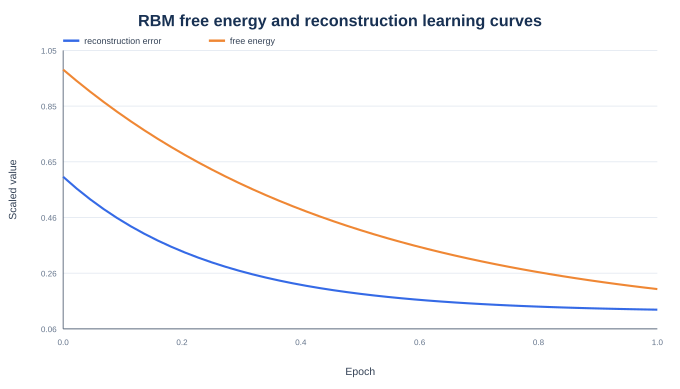

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import expit

rng=np.random.default_rng(25)
def make_patterns(n=240):
    data=[]
    for i in range(n):
        image=np.zeros((8,8))
        kind=i%4
        if kind==0:image[2:6,:]=1
        elif kind==1:image[:,2:6]=1
        elif kind==2:np.fill_diagonal(image,1);np.fill_diagonal(np.fliplr(image),1)
        else:image[2:6,2:6]=1
        image=np.clip(image+rng.normal(0,.12,image.shape),0,1)
        data.append((rng.random(image.size)<image.ravel()).astype(float))
    return np.array(data)
V=make_patterns()
n_visible=V.shape[1];n_hidden=24
W=rng.normal(0,.02,(n_visible,n_hidden));a=np.zeros(n_visible);b=np.zeros(n_hidden)
def p_h(v):return expit(v@W+b)
def p_v(h):return expit(h@W.T+a)
def energy(v,h):return -v@a-h@b-v@W@h.T
def free_energy(v):return -v@a-np.logaddexp(0,v@W+b).sum(axis=1)

errors=[];energies=[]
for epoch in range(35):
    rng.shuffle(V)
    for start in range(0,len(V),30):
        v0=V[start:start+30]
        ph0=p_h(v0);h0=(rng.random(ph0.shape)<ph0).astype(float)
        pv1=p_v(h0);v1=(rng.random(pv1.shape)<pv1).astype(float)
        ph1=p_h(v1)
        W+=.04*(v0.T@ph0-v1.T@ph1)/len(v0)
        a+=.04*np.mean(v0-v1,axis=0);b+=.04*np.mean(ph0-ph1,axis=0)
    recon=p_v(p_h(V))
    errors.append(np.mean((V-recon)**2));energies.append(np.mean(free_energy(V)))
print("Energy of first visible-hidden pair:",round(energy(V[0],(p_h(V[:1])>.5).astype(float)[0]),3))
fig,axes=plt.subplots(1,2,figsize=(9,3))
axes[0].plot(energies);axes[0].set(title="Average free energy",xlabel="Epoch")
axes[1].plot(errors);axes[1].set(title="Reconstruction error",xlabel="Epoch")
for ax in axes:ax.grid(alpha=.2)
plt.tight_layout();plt.show()
recon=(p_v(p_h(V[:8]))>.5).astype(float)
fig,axes=plt.subplots(2,8,figsize=(10,3))
for i in range(8):
    axes[0,i].imshow(V[i].reshape(8,8),cmap="gray");axes[1,i].imshow(recon[i].reshape(8,8),cmap="gray")
    axes[0,i].axis("off");axes[1,i].axis("off")
axes[0,0].set_ylabel("original");axes[1,0].set_ylabel("reconstructed")
plt.tight_layout();plt.show()